version: 0.1.2

In [242]:
from __future__ import print_function
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import yaml
from mpl_toolkits.mplot3d import Axes3D
import plotly.graph_objects as go
from matplotlib.ticker import FuncFormatter
from PIL import Image, ImageDraw, ImageFont, ImageSequence
from pathlib import Path
import os
import re
import math

In [311]:
#sys_dict = {"version":'0.1.1',"Hamiltonian":"MoS2","Nk":10,"kxlist":np.linspace(-np.pi,np.pi,10),"kylist":np.linspace(-np.pi,np.pi,10),"NQ":19,"Qxlist":np.linspace(-2*np.pi,2*np.pi,19),"Qylist":np.linspace(-2*np.pi,2*np.pi,19),"U":16,"epsilon":1e-6, "Bands": 2}
config = {"version":"0.1.2", "Hamiltonian":"Modified MoS2","Interaction":("Constant",1,1),"Nk":150,"U":16,"epsilon":1e-6,"Bands":3}
#"Interaction":("Constant",1,1)
#"Interaction":("Coulomb",None,None)
with open('config.yml', 'w') as outfile:
   yaml.dump(config, outfile, default_flow_style=False)
GetConfig('config.yml')

In [273]:
#get config
def GetConfig(filename = "Data/11.06.2025/config.yml"):
    global sys_dict
    with open(filename, 'r') as stream:
        sys_dict = yaml.load(stream, Loader=yaml.UnsafeLoader)
    Nk=sys_dict["Nk"]
    sys_dict["kxlist"] = np.linspace(0,2*np.pi,Nk)
    sys_dict["kylist"] = np.linspace(0,4*np.pi/np.sqrt(3),Nk)
    sys_dict["NQ"] = 2*Nk-1
    sys_dict["Qxlist"] = np.linspace(0,4*np.pi,2*Nk-1)
    sys_dict["Qylist"] = np.linspace(0,8*np.pi/np.sqrt(3),2*Nk-1)
#for the py file
def SaveConfig(config_file):
    keys_to_save = ["version", "Hamiltonian", "Nk", "U", "epsilon", "Bands","Interaction"]
    config = {key: sys_dict[key] for key in keys_to_save if key in sys_dict}
    with open(config_file, 'w') as outfile:
        yaml.dump(config, outfile, default_flow_style=False)

In [244]:
def PiFormatter(value, tick_number):#just to be cute
    return f"{np.round(value/np.pi,3)}π"
def PiFormatter_plotly(values):
    labels = []
    for v in values:
        labels.append(f"{np.round(v/np.pi,3)}π")
        #if np.isclose(v, 0):
        #    labels.append("0")
        #elif np.isclose(v, np.pi):
        #    labels.append("π")
        #elif np.isclose(v, -np.pi):
        #    labels.append("-π")
        #elif np.isclose(v % (2*np.pi), 0):
        #    labels.append(f"{int(v/(np.pi))}π")
        #else:
        #    labels.append(f"{np.round(v/np.pi,2)}π")
    return labels

In [245]:
%matplotlib widget

# Non interacting picture

## Solve non-interacting BZ

### Hamiltonians

In [304]:
def ChernHamiltonian(kx,ky):
    pauli_mat =[np.array([[0,1],[1,0]]), np.array([[0,-1j],[1j,0]]), np.array([[1,0],[0,-1]])]
    M = -1.1
    return np.sin(kx)*pauli_mat[0] + np.sin(ky)*pauli_mat[1] + (M+np.cos(kx)+np.cos(ky))*pauli_mat[2]
# 10.1103/PhysRevB.88.085433
def TNNMoS_2Hamiltonian(kx,ky):
    alpha =0.5*kx
    beta = (np.sqrt(3)/2)*ky
    epsilon1 =0.683
    epsilon2 =1.707
    t0 = -0.146
    t1 = -0.114
    t2 = 0.506
    t11 = 0.085
    t12 = 0.162
    t22 = 0.073
    r0 = 0.060
    r1 = -0.236
    r2 = 0.067
    r11 = 0.016
    r12 = 0.087
    u0 = -0.038
    u1 = 0.046
    u2 = 0.001
    u11 = 0.266
    u12 = -0.176
    u22 = -0.150
    h0 = (epsilon1 +
          2 * t0 * (2 * np.cos(alpha) * np.cos(beta) + np.cos(2 * alpha)) +
          2 * r0 * (2 * np.cos(3 * alpha) * np.cos(beta) + np.cos(2 * beta)) +
          2 * u0 * (2 * np.cos(2 * alpha) * np.cos(2 * beta) + np.cos(4 * alpha)))

    h1_real = (-2 * np.sqrt(3) * t2 * np.sin(alpha) * np.sin(beta) +
               2 * (r1 + r2) * np.sin(3 * alpha) * np.sin(beta) -
               2 * np.sqrt(3) * u2 * np.sin(2 * alpha) * np.sin(2 * beta))

    h1_imag = (2 * t1 * np.sin(alpha) * (2 * np.cos(alpha) + np.cos(beta)) +
               2 * (r1 - r2) * np.sin(3 * alpha) * np.cos(beta) +
               2 * u1 * np.sin(2 * alpha) * (2 * np.cos(2 * alpha) + np.cos(2 * beta)))

    h1 = h1_real + 1j * h1_imag

    h2_real = (2 * t2 * (np.cos(2 * alpha) - np.cos(alpha) * np.cos(beta)) -
               (2 / np.sqrt(3)) * (r1 + r2) * (np.cos(3 * alpha) * np.cos(beta) - np.cos(2 * beta)) +
               2 * u2 * (np.cos(4 * alpha) - np.cos(2 * alpha) * np.cos(2 * beta)))

    h2_imag = (2 * np.sqrt(3) * t1 * np.cos(alpha) * np.sin(beta) +
               (2 / np.sqrt(3)) * np.sin(beta) * (r1 - r2) * (np.cos(3 * alpha) + 2 * np.cos(beta)) +
               2 * np.sqrt(3) * u1 * np.cos(2 * alpha) * np.sin(2 * beta))

    h2 = h2_real + 1j * h2_imag

    h11 = (epsilon2 +
           (t11 + 3 * t22) * np.cos(alpha) * np.cos(beta) +
           2 * t11 * np.cos(2 * alpha) +
           4 * r11 * np.cos(3 * alpha) * np.cos(beta) +
           2 * (r11 + np.sqrt(3) * r12) * np.cos(2 * beta) +
           (u11 + 3 * u22) * np.cos(2 * alpha) * np.cos(2 * beta) +
           2 * u11 * np.cos(4 * alpha))

    h12_real = (np.sqrt(3) * (t22 - t11) * np.sin(alpha) * np.sin(beta) +
                4 * r12 * np.sin(3 * alpha) * np.sin(beta) +
                np.sqrt(3) * (u22 - u11) * np.sin(2 * alpha) * np.sin(2 * beta))

    h12_imag = (4 * t12 * np.sin(alpha) * (np.cos(alpha) - np.cos(beta)) +
                4 * u12 * np.sin(2 * alpha) * (np.cos(2 * alpha) - np.cos(2 * beta)))

    h12 = h12_real + 1j * h12_imag

    h22 = (epsilon2 + 
           (3 * t11 + t22) * np.cos(alpha) * np.cos(beta) +
           2 * t22 * np.cos(2 * alpha) +
           2 * r11 * (2 * np.cos(3 * alpha) * np.cos(beta) + np.cos(2 * beta)) +
           (2 / np.sqrt(3)) * r12 * (4 * np.cos(3 * alpha) * np.cos(beta) - np.cos(2 * beta)) +
           (3 * u11 + u22) * np.cos(2 * alpha) * np.cos(2 * beta) +
           2 * u22 * np.cos(4 * alpha))

    # Construct the Hamiltonian matrix
    H_0 = np.array([
        [h0, h1, h2],
        [np.conj(h1), h11, h12],
        [np.conj(h2), np.conj(h12), h22]
    ])
    #Bz= 0.08
    #sz = np.array([[1, 0], [0, -1]])
    #HZ_spin = Bz*sz
    #HZ = np.kron(np.eye(3), HZ_spin) #zeeman effect
    #Add SOC
    lambda_soc =  0.073
    Lz = np.array([[0, 0, 0],
                   [0, 0, 2j],
                   [0, -2j, 0]])
    
    # SOC matrix
    SOC_block = (lambda_soc/2) * Lz
    
    # Expand to spin basis
    Hamiltonian = np.block([
        [H_0 +SOC_block, np.zeros_like(H_0)],
        [np.zeros_like(H_0), H_0 - SOC_block]
    ]) #+ HZ    
    #return Hamiltonian
    return H_0

def ModifiedMoS_2Hamiltonian(kx,ky):
    alpha =0.5*kx
    beta = (np.sqrt(3)/2)*ky
    epsilon1 =0.683
    epsilon2 =1.707
    t0 = -0.146
    t1 = -0.114
    t2 = 0.506
    t11 = 0.085
    t12 = 0.162
    t22 = 0.073
    r0 = 0.060
    r1 = -0.236
    r2 = 0.067
    r11 = 0.016
    r12 = 0.087
    u0 = -0.038
    u1 = 0.046
    u2 = 0.001
    u11 = 0.266
    u12 = -0.176
    u22 = -0.150
    delta = 0.1
    h0 = (epsilon1 +
          2 * t0 * (2 * np.cos(alpha) * np.cos(beta) + np.cos(2 * alpha)) +
          2 * r0 * (2 * np.cos(3 * alpha) * np.cos(beta) + np.cos(2 * beta)) +
          2 * u0 * (2 * np.cos(2 * alpha) * np.cos(2 * beta) + np.cos(4 * alpha)))

    h1_real = (-2 * np.sqrt(3) * t2 * np.sin(alpha) * np.sin(beta) +
               2 * (r1 + r2) * np.sin(3 * alpha) * np.sin(beta) -
               2 * np.sqrt(3) * u2 * np.sin(2 * alpha) * np.sin(2 * beta))

    h1_imag = (2 * t1 * np.sin(alpha) * (2 * np.cos(alpha) + np.cos(beta)) +
               2 * (r1 - r2) * np.sin(3 * alpha) * np.cos(beta) +
               2 * u1 * np.sin(2 * alpha) * (2 * np.cos(2 * alpha) + np.cos(2 * beta)))

    h1 = h1_real + 1j * h1_imag

    h2_real = (2 * t2 * (np.cos(2 * alpha) - np.cos(alpha) * np.cos(beta)) -
               (2 / np.sqrt(3)) * (r1 + r2) * (np.cos(3 * alpha) * np.cos(beta) - np.cos(2 * beta)) +
               2 * u2 * (np.cos(4 * alpha) - np.cos(2 * alpha) * np.cos(2 * beta)))

    h2_imag = (2 * np.sqrt(3) * t1 * np.cos(alpha) * np.sin(beta) +
               (2 / np.sqrt(3)) * np.sin(beta) * (r1 - r2) * (np.cos(3 * alpha) + 2 * np.cos(beta)) +
               2 * np.sqrt(3) * u1 * np.cos(2 * alpha) * np.sin(2 * beta))

    h2 = h2_real + 1j * h2_imag

    h11 = (epsilon2 +
           (t11 + 3 * t22) * np.cos(alpha) * np.cos(beta) +
           2 * t11 * np.cos(2 * alpha) +
           4 * r11 * np.cos(3 * alpha) * np.cos(beta) +
           2 * (r11 + np.sqrt(3) * r12) * np.cos(2 * beta) +
           (u11 + 3 * u22) * np.cos(2 * alpha) * np.cos(2 * beta) +
           2 * u11 * np.cos(4 * alpha) +delta)

    h12_real = (np.sqrt(3) * (t22 - t11) * np.sin(alpha) * np.sin(beta) +
                4 * r12 * np.sin(3 * alpha) * np.sin(beta) +
                np.sqrt(3) * (u22 - u11) * np.sin(2 * alpha) * np.sin(2 * beta))

    h12_imag = (4 * t12 * np.sin(alpha) * (np.cos(alpha) - np.cos(beta)) +
                4 * u12 * np.sin(2 * alpha) * (np.cos(2 * alpha) - np.cos(2 * beta)))

    h12 = h12_real + 1j * h12_imag

    h22 = (epsilon2 + 
           (3 * t11 + t22) * np.cos(alpha) * np.cos(beta) +
           2 * t22 * np.cos(2 * alpha) +
           2 * r11 * (2 * np.cos(3 * alpha) * np.cos(beta) + np.cos(2 * beta)) +
           (2 / np.sqrt(3)) * r12 * (4 * np.cos(3 * alpha) * np.cos(beta) - np.cos(2 * beta)) +
           (3 * u11 + u22) * np.cos(2 * alpha) * np.cos(2 * beta) +
           2 * u22 * np.cos(4 * alpha)-delta)

    # Construct the Hamiltonian matrix
    H_0 = np.array([
        [h0, h1, h2],
        [np.conj(h1), h11, h12],
        [np.conj(h2), np.conj(h12), h22]
    ])
    #Bz= 0.08
    #sz = np.array([[1, 0], [0, -1]])
    #HZ_spin = Bz*sz
    #HZ = np.kron(np.eye(3), HZ_spin) #zeeman effect
    #Add SOC
    lambda_soc =  0.073
    Lz = np.array([[0, 0, 0],
                   [0, 0, 2j],
                   [0, -2j, 0]])
    
    # SOC matrix
    SOC_block = (lambda_soc/2) * Lz
    
    # Expand to spin basis
    Hamiltonian = np.block([
        [H_0 +SOC_block, np.zeros_like(H_0)],
        [np.zeros_like(H_0), H_0 - SOC_block]
    ]) #+ HZ    
    #return Hamiltonian
    return H_0

In [312]:
def SolveH(kx,ky):
    H_config = sys_dict["Hamiltonian"]
    if H_config == "MoS2":
        H = TNNMoS_2Hamiltonian(kx,ky)
    elif H_config == "QWZ":
        H = ChernHamiltonian(kx,ky)
    elif H_config == "Modified MoS2":
        H = ModifiedMoS_2Hamiltonian(kx,ky)
    else:
        raise ValueError("Could not parse acceptable Hamiltonian")
    val,evec = np.linalg.eigh(H) #THIS LINE FUCK THIS LINE
    sorted_indices = np.argsort(val)
    sorted_val = val[sorted_indices]
    sorted_evec = evec[:, sorted_indices]
    return sorted_val,sorted_evec
    #return val,evec
def SolveBzNoninteracting():
    kx = sys_dict["kxlist"]
    ky = sys_dict["kylist"]
    n_points = sys_dict["Nk"]
    n_bands = sys_dict["Bands"]
    wf_BZ = np.zeros((n_points,n_points,n_bands,n_bands), dtype=complex) #kx,ky,orbital weight, band
    eval_BZ = np.zeros((n_points,n_points,n_bands))
    for i in range(n_points):
        for j in range(n_points):      
            (val,vec)=SolveH(kx[i],ky[j])
            #for l in range(vec.shape[1]):
            #    phase = np.angle(vec[0,l])
            #    vec = vec * np.exp(-1j*phase)
            eval_BZ[i,j] = val
            wf_BZ[i,j] = vec
    return eval_BZ, wf_BZ

## Berry Curvature over BZ

In [247]:
#recieves ni_wf[:,:,:,n] where n is the desired band
def GetBerryCurvature1band(u):
    N = u.shape[0] #assumes u.shape[N,N,:]
    link_x=np.zeros([N,N], dtype="complex")
    link_y=np.zeros([N,N], dtype="complex")
    BC=np.zeros([N,N], dtype="complex")
    #epsilon = sys_dict["epsilon"]
    for i in range(N):
        for j in range(N):
            link_x[i,j]=(u[i-1,j,:].conj().T @ u[i,j,:])/np.abs(u[i-1,j,:].conj().T @ u[i,j,:])
            link_y[i,j]=(u[i,j-1,:].conj().T @ u[i,j,:])/np.abs(u[i,j-1,:].conj().T @ u[i,j,:])
    for i in range(N):
        for j in range(N):
            val = np.log(link_x[i,j]*link_y[i-1,j]/(link_x[i,j-1]*link_y[i,j]))
            #commented code to erase undefined points at band crossings
            #if not math.isnan(val):
            BC[i,j] = val
            #else:
                #BC[i,j]=BC[i,j-1]
    C=np.sum(BC)/(2*1j*np.pi)
    return BC,C

In [267]:
def GraphBerryCurvature(berry_curvature,C,output_folder):
    x = sys_dict["Qxlist"]
    y = sys_dict["Qylist"]

    # Create a fresh figure and axis
    fig, ax = plt.subplots(figsize=(6, 5))

    # Plot the imaginary part of the Berry curvature
    im = ax.imshow(
        np.imag(berry_curvature),
        cmap="viridis",
        aspect="equal",
        vmin=-0.005,
        vmax=0.005,
        origin="lower",
        extent=[x[0], x[-1], y[0], y[-1]],
    )

    # Axis formatting
    ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
    ax.yaxis.set_major_formatter(FuncFormatter(PiFormatter))

    # Labels and title
    ax.set_title("Berry Curvature")
    ax.set_xlabel("Qx")
    ax.set_ylabel("Qy")

    # Colorbar attached to this figure
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Strength")

    # Save and show
    output_path = os.path.join(output_folder, f"BC,SOC, C={np.round(C)}.png")
    fig.savefig(output_path)
    #plt.close()
    #plt.show()

In [249]:
#need to be updated if not scrapped.
def GraphEnergies(evals):
    plt.close('all')
    plt.imshow(evals)
    plt.title('Energy for M')
    plt.xlabel('Nx')
    plt.ylabel('Ny')
    cbar = plt.colorbar()
    cbar.set_label('Field Strength')
    plt.show()

## Check Band Structure

In [250]:
def InterpEquidistant(points , n):
    x = points[:, 0]
    y = points[:, 1]
    
    # Linear length on the line
    distance = np.cumsum(np.sqrt( np.ediff1d(x, to_begin=0)**2 + np.ediff1d(y, to_begin=0)**2 ))
    distance = distance/distance[-1]
    
    fx, fy = interp1d( distance, x ), interp1d( distance, y )
    
    alpha = np.linspace(0, 1, n)
    x_regular, y_regular = fx(alpha), fy(alpha)
    path = np.column_stack((x_regular, y_regular))
    return path

In [293]:
def GraphBands(output_folder):
    #define high symmetry points
    H_config = sys_dict["Hamiltonian"]
    if H_config == "MoS2" or H_config == "Modified MoS2":
        Gamma = np.array([0.0, 0.0])  # Gamma point
        K = np.array([4*np.pi/3, 0.0])  # K point
        M = np.array([np.pi, np.pi/np.sqrt(3)])  # M point
    elif H_config == "QWZ":
        Gamma = np.array([0.0, 0.0])  # Gamma point
        K = np.array([np.pi, 0.0])  # K point
        M = np.array([np.pi, np.pi])  # M point
    else:
        raise ValueError("Could not parse acceptable Hamiltonian")
    points = np.array([Gamma, K, M, Gamma])
    k_path = InterpEquidistant(points, 300)
    evals = []
    for k in k_path:
        val,vec = SolveH(k[0],k[1])
        evals.append(val)
    # Convert evals to NumPy array for easy plotting
    evals = np.array(evals)  # Shape: (300, num_bands)
    
    # Compute cumulative distances along k-path
    distances = [0.0]  # First point is at distance 0
    for i in range(1, len(k_path)):
        dist = np.linalg.norm(k_path[i] - k_path[i - 1])  # Euclidean distance
        distances.append(distances[-1] + dist)
    
    distances = np.array(distances)  # Convert to NumPy array
    
    # Find tick positions for Γ, K, and M in the distance array
    tick_positions = [0]  # Start with first point (Gamma)
    tick_labels = ["Γ"]  # Gamma point label
    
    cumulative_length = 0
    for i in range(len(points) - 1):
        segment_length = np.linalg.norm(points[i+1] - points[i])
        cumulative_length += segment_length
        tick_positions.append(cumulative_length)
    
    tick_labels.extend(["K", "M", "Γ"])  # Labels for symmetry points
    
    fig, ax = plt.subplots(figsize=(6, 5))

    # Loop over all bands
    for band in range(evals.shape[1]):
        ax.plot(distances, evals[:, band], color="black")

    # Add vertical lines at symmetry points
    for pos in tick_positions:
        ax.axvline(x=pos, color="gray", linestyle="--", linewidth=0.5)

    # Set x-axis ticks and labels
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels)

    # Labels and title
    ax.set_xlabel("Wavevector k")
    ax.set_ylabel("Energy (eV)")  # Adjust units if needed
    ax.set_title(f"Band Structure {H_config}")

    # Save and show
    output_path = os.path.join(output_folder, "bandsSOC.png")
    fig.savefig(output_path)

# Interacting picture

## The Plan
following 10.1103/PhysRevB.91.075310
1) Solve the Hamiltonian for the entire $(k_x,k_y)$ grid in the non interacting picture (above)
2) Function create the Hamiltonian with interaction (direct and exchange terms) using the non interacting eigenvectors eq (6)

$D_{vv'}^{cc'}(\vec{k}\vec{k'}\vec{Q})=\frac{1}{N}V_{\vec{k}-\vec{k'}}\left(u^{\dagger}_{\vec{k}+\vec{Q}}u_{\vec{k'}+\vec{Q}}\right)_{cc'}\left(u^{\dagger}_{\vec{k'}}u_{\vec{k}}\right)_{v'v}$

$X_{vv'}^{cc'}(\vec{k}\vec{k'}\vec{Q})=\frac{1}{N}V_{\vec{Q}}\left(u^{\dagger}_{\vec{k}+\vec{Q}}u_{\vec{k}}\right)_{cv}\left(u^{\dagger}_{\vec{k'}}u_{\vec{k'}+\vec{Q}}\right)_{v'c'}$

Use the non interacting eigenvalues as well as D and X in the following equation (5)

$
\begin{equation}
\langle v, c, \vec{k}, \vec{Q} | H | v', c', \vec{k'}, \vec{Q'} \rangle = \delta_{vv'} \delta_{cc'} \delta_{kk'} \left( \epsilon_{(\vec{k} + \vec{Q}) c} - \epsilon_{\vec{k} v}\right) - (D - X)^{c c'}_{v v'} (\vec{k}, \vec{k'}, \vec{Q}) 
\end{equation}
$

3) loop over every Q leading to eigenvalues $\epsilon_Q$ and eigenvectors $F(Q,P)$
4) graph e_q and integrated F

### Step 1 
use the previous functions to get 2D eigenfunc matrix of the entire BZ, run non pythTB block for entire BZ.<br>
eigenvalues [k_x][k_y][n]. conduction: n = 0, valance: n = 1.<br>
eigenvectors [kx][ky][j][n] x: j=0, y: j=1

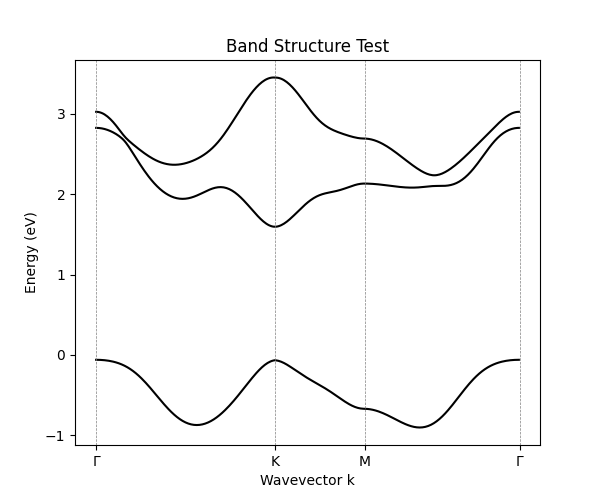

In [305]:
#GetConfig()
GraphBands("Images")

(2+3.837531471060582e-15j)


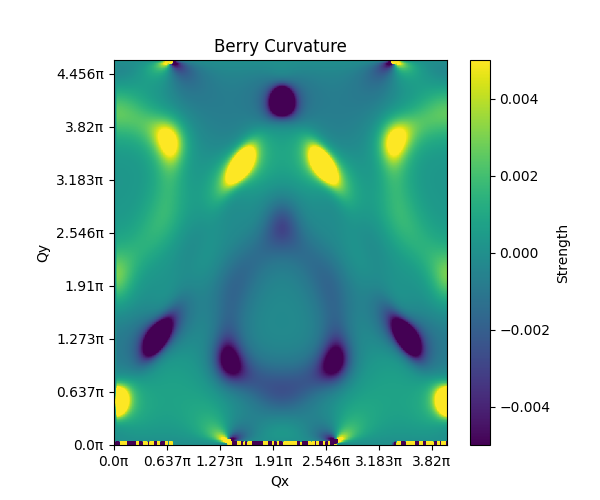

In [308]:
#Use berry curvature to make sure eigvecs are correct
ni_eval, ni_wf = SolveBzNoninteracting()
BC, C = GetBerryCurvature1band(ni_wf[:,:,:,2])
print(C)
GraphBerryCurvature(BC,C, "Images")
#check the energies look ok
#GraphEnergies(_ni_evals[:,:,0])

### Try to show how much the bands cross

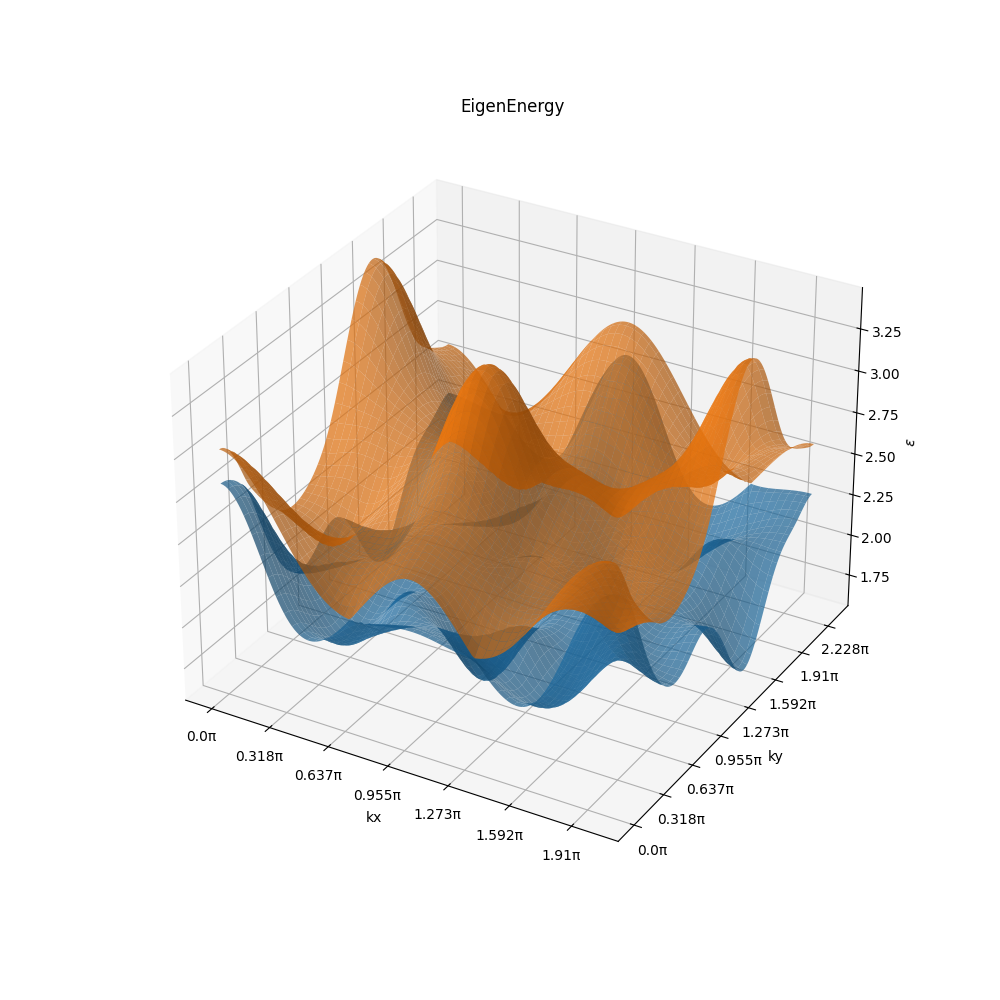

In [309]:
kx_list = sys_dict["kxlist"]
ky_list = sys_dict["kylist"]
kx_mesh, ky_mesh = np.meshgrid(kx_list,ky_list)
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')
for i in range(1,3): #choose bands
    e_sheet = ni_eval[:,:,i]
    ax.plot_surface(kx_mesh, ky_mesh, e_sheet, alpha=0.7, label=f"band {i}")
ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
ax.yaxis.set_major_formatter(FuncFormatter(PiFormatter))
ax.set_xlabel('kx')
ax.set_ylabel('ky')
ax.set_zlabel(r'$\epsilon$')
plt.title("EigenEnergy")
#output_path = os.path.join(output_folder, f'Energys3D n={n}.png')
#plt.savefig(output_path)
plt.show()

Number of near-degeneracies (band 2 ≈ band 1): 4


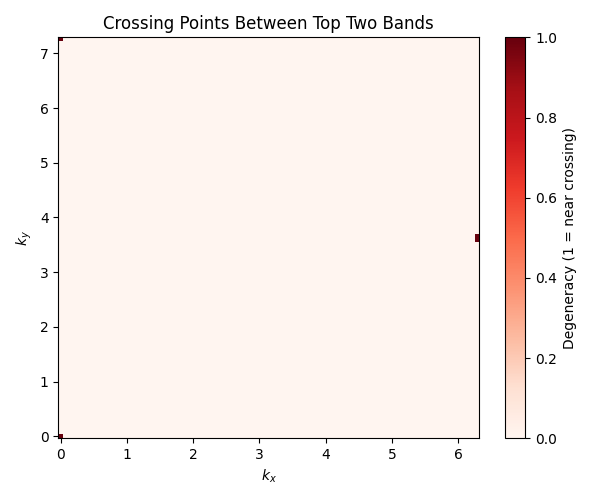

In [46]:
# Load data
eig = ni_eval  # shape: (Nkx, Nky, 3)
kx_list = sys_dict["kxlist"]    # shape: (Nkx,)
ky_list = sys_dict["kylist"]    # shape: (Nky,)
# Threshold for near-degeneracy
epsilon = 1e-3

# Find near crossings between top two bands
delta = np.abs(eig[:, :, 2] - eig[:, :, 1])
crossing_mask = delta < epsilon
num_crossings = np.sum(crossing_mask)
print(f"Number of near-degeneracies (band 2 ≈ band 1): {num_crossings}")

# Build 2D coordinate grid
KX, KY = np.meshgrid(kx_list, ky_list, indexing='ij')  # shape: (Nkx, Nky)

# Plot
plt.figure(figsize=(6, 5))
plt.pcolormesh(KX, KY, crossing_mask, cmap='Reds', shading='auto')
plt.title("Crossing Points Between Top Two Bands")
plt.xlabel(r"$k_x$")
plt.ylabel(r"$k_y$")
plt.colorbar(label='Degeneracy (1 = near crossing)')
plt.tight_layout()
plt.show()


### Step 2
Define func get_H(Q,wf_array) which returns the 4D H tensor for each Q depending on the wavefunctions of the non interacting problem.
notes: currently assumes a 2 band system, therfore no consideration for difference between different bands c=c' v=v'.

#### WIP
in 2band $H_{cc'}^{vv'} == H_c^v$ currently calculates for v=v'=0 c=c'=1
in multiple bands we define ahead of time which bands are valence and which ar conduction and loop over those bands.
4 dimensions c,c',v,v': say vband =[0,1] cband=[2,3] are the indices of the valance and conduction bands then we have two options for each v,v' (either 0 or 1 each) and two options for c,c' (either 2,3 each). This means its H[(kx,ky),(kx_tag,ky_tag),c,c',v,v'], after that we need to squish this H to H_squish1[(kx,ky),(kx_tag,ky_tag),cc',vv'] -> H_squish2[[(kx,ky),(kx_tag,ky_tag),cc'vv']-> H_squish3[(kx,ky)(kx_tag,ky_tag),cc'vv']-> squish4 [(kx,ky)(kx',ky')cc'vv']-> squish5 [(kx,ky)kx'ky'cc'vv'] (where squish 5 is just like the first squish from 4d to 2d. basically we go from 8D to 2D in a manner that is bijective.

In [43]:
#TODO: fix this so it works on all bands
def GetH2Band(Qx_indx,Qy_indx,wf_ni, ni_evals,half_dQx,half_dQy):
    U = sys_dict["U"]
    epsilon = sys_dict["epsilon"]
    kxlist = sys_dict["kxlist"]
    kylist = sys_dict["kylist"]
    Qxlist = sys_dict["Qxlist"]
    Qylist = sys_dict["Qylist"]
    NQ = sys_dict["NQ"]
    Nk = sys_dict["Nk"]
    interaction = sys_dict["Interaction"]
    #H = np.zeros((NQ,Nk,NQ,Nk), dtype = complex) #H(k,k')
    H = np.zeros((Nk,Nk,Nk,Nk), dtype = complex) #H(k,k')
    for kx in range(Nk):
        for ky in range(Nk):
            for kx_tag in range(Nk):
                for ky_tag in range(Nk):
                    #precalculate the whole modulu buisness
                    kx_Qx = (kx+Qx_indx)%Nk  
                    kx_Qx_tag = (kx_tag+Qx_indx)%Nk
                    ky_Qy = (ky+Qy_indx)%Nk
                    ky_Qy_tag = (ky_tag+Qy_indx)%Nk
                    if kx==kx_tag and ky==ky_tag:
                        e = ni_evals[kx_Qx][ky_Qy][0]- ni_evals[kx][ky][1]
                    else:
                        e = 0
                    if interaction[0] == "Coulomb":
                        V_d = 1/(pow(Nk,2)*(np.sqrt((pow(kxlist[kx-kx_tag],2) + pow(kylist[ky-ky_tag],2))))+epsilon)
                        V_x = 1/(pow(Nk,2)*(np.sqrt(pow(Qxlist[Qx_indx]+half_dQx,2)+pow(Qylist[Qy_indx]+half_dQy,2)))+epsilon)
                    elif interaction[0] == "Constant":
                        V_d = interaction[1]
                        V_x = interaction[2]
                    D = U*V_d*np.vdot(wf_ni[kx_Qx,ky_Qy,:,0],wf_ni[kx_Qx_tag,ky_Qy_tag,:,0])*np.vdot(wf_ni[kx_tag,ky_tag,:,1],wf_ni[kx,ky,:,1]) #N=1?
                    X = U*V_x*np.vdot(wf_ni[kx_Qx,ky_Qy,:,1],wf_ni[kx,ky,:,0])*np.vdot(wf_ni[kx_tag,ky_tag,:,0],wf_ni[kx_Qx_tag,ky_Qy_tag,:,1])
                    H[kx,ky,kx_tag,ky_tag] = e - (D-X)
    return H

In [ ]:
def GetH(Qx_indx,Qy_indx,wf_ni, ni_evals,half_dQx,half_dQy,v_indx = [0,1],c_indx=[2,3]) #rn manually setting what bands are cond and val but i can also look at all bands onder 0 or something more general
 U = sys_dict["U"]
    epsilon = sys_dict["epsilon"]
    kxlist = sys_dict["kxlist"]
    kylist = sys_dict["kylist"]
    Qxlist = sys_dict["Qxlist"]
    Qylist = sys_dict["Qylist"]
    NQ = sys_dict["NQ"]
    Nk = sys_dict["Nk"]
return

### Step 3
Loop over every Q from $-2\pi$ to $2\pi$ using the same difference between k's (so if k is 20x20 Q is 40x40). Flatten H to a 2D matrix. Solve the eigensystem of the 2D matrix, save the eigenvalues of Q.

In [15]:
def SolveInteracting(ni_evals,ni_wf):
    NQ = sys_dict["NQ"]
    Qxlist = sys_dict["Qxlist"]
    Qylist = sys_dict["Qylist"]
    dQx = np.abs(Qxlist[1] - Qxlist[0])
    dQy = np.abs(Qylist[1] - Qylist[0])
    Nk = sys_dict["Nk"]
    eQ_matrix = np.zeros((NQ,NQ,Nk*Nk))
    f_matrix = np.zeros((NQ,NQ,Nk*Nk,Nk*Nk),dtype=np.complex128)
    for i in range(NQ):#Qx
        for j in range(NQ):#Qy
            H_Q = GetH2Band(i,j,ni_wf,ni_evals,dQx/2,dQy/2)
            H_Q2D = Flatten4D(H_Q)
            e_Q, f_Q = np.linalg.eigh(H_Q2D)
            # Sort the eigenvalues and reorder eigenvectors accordingly
            sorted_indices = np.argsort(e_Q)
            sorted_e_Q = e_Q[sorted_indices]
            sorted_f_Q = f_Q[:, sorted_indices]
            sorted_e_Q = np.real(sorted_e_Q)
            eQ_matrix[i,j]= sorted_e_Q
            f_matrix[i,j] = sorted_f_Q
    end_time = time.time()
    return(eQ_matrix,f_matrix)

note about flattening, we go from $H_{ijkl} -> H_{i'j'}$, I want the first index to represent k and the second to represent k'. in order to do that I flattened it in such a way that $i' = i*N_{ky} + j$ and $j' = k*N_{ky} +l$ I feel like this makes the most sense. To unwind simply take floor or modulu of the index by N.

In [38]:
def Flatten4D(array4D):
    Nk = sys_dict["Nk"]
    imax,jmax,kmax,lmax = Nk,Nk,Nk,Nk #this can be made more generic but im trying to minmax efficiency a little bit
    # Flatten the 4D array to a 2D array using explicit index mapping
    array2D = np.empty((imax * jmax, kmax * lmax), dtype=complex)
    for i in range(imax):
        for j in range(jmax):
            for k in range(kmax):
                for l in range(lmax):
                    # Map 4D indices to 2D indices
                    row = i * jmax + j
                    col = k * lmax + l
                    array2D[row, col] = array4D[i, j, k, l]
    return array2D

# Verify index mapping
#for i in range(imax):
#    for j in range(jmax):
#        for k in range(kmax):
#            for l in range(lmax):
#                if array2D[i * jmax + j][k * lmax + l] != array4D[i][j][k][l]:
#                    print("Error in mapping")

In [12]:
#unused rn, Unflatten
def UnFlatten2D(array2D):
    # Reverse the flattening process
    for row in range(imax * jmax):
        for col in range(kmax * lmax):
            # Convert 2D indices (row, col) back to 4D indices (i, j, k, l)
            i = row // jmax
            j = row % jmax
            k = col // lmax
            l = col % lmax
            
            # Assign the value from 2D array to 4D array
            array4D[i, j, k, l] = array2D[row, col]
    return array4D

### Step 4
graphs

In [180]:
def Graph3D(eQ_matrix,n,output_folder):
    #eQ_matrix is the completed exciton eigenenergies grid while n is the number of energy levels we wish to show
    Qxlist = sys_dict["Qxlist"]
    Qylist = sys_dict["Qylist"]
    Qx_mesh, Qy_mesh = np.meshgrid(Qxlist,Qylist)
    #sys_dict["Qxlist"] = np.linspace(0,4*np.pi,2*Nk-1)
    #sys_dict["Qylist"] = np.linspace(0,8*np.pi/np.sqrt(3),2*Nk-1)
    fig = go.Figure()
    for i in range(n): #choose bands
        eQ_sheet = eQ_matrix[:,:,i]
        fig.add_surface(
            x=Qx_mesh, y=Qy_mesh, z=eQ_sheet,
            opacity=0.7,
            name=f"band {i}",
            colorscale="Viridis"
        )

    tick_labels_x = PiFormatter_plotly(Qxlist)
    tick_labels_y = PiFormatter_plotly(Qylist)
    fig.update_layout(
        scene=dict(
            xaxis=dict(
                title="Qx",
                tickvals=Qxlist,
                ticktext=tick_labels_x
            ),
            yaxis=dict(
                title="Qy",
                tickvals=Qylist,
                ticktext=tick_labels_y
            ),
            zaxis=dict(title="ε(Q)")
        ),
        title="Exciton EigenEnergy"
    )

    output_path = os.path.join(output_folder, f"Energys3D_n={n}.html")
    fig.write_html(output_path)
    return fig

In [181]:
#Only for chern insulator rn
def GraphQxConst(eQ_matrix,output_folder):
    fig, ax = plt.subplots(figsize=(6, 6))
    #Qxlist= sys_dict["Qxlist"]
    Qylist = sys_dict["Qylist"]
    Nk= sys_dict["Nk"]
    epsilon = sys_dict["epsilon"]
    U= sys_dict["U"]
    #M = sys_dict["M"]
    rows, cols, n = eQ_matrix.shape
    center_row = rows // 2
    center_plus1 = rows - center_row
    #band = np.zeros(3*(center_plus1))
    count = n
    for i in range(count):
       # line1 = [eQ_matrix[center_row + j-1, center_row + j-1,i] for j in range(center_plus1)]
       # line2 = [eQ_matrix[rows-1, rows - j-2,i] for j in range(center_plus1-1)] #-2 and -1 to avoid using the same point twice
       # line3 = [eQ_matrix[rows - j-1, center_row-1,i] for j in range(center_plus1-1)]
       # band = line1 + line2 + line3
        band = [eQ_matrix[center_row,j,i] for j in range(cols)]
        ax.plot(Qylist,band)

    #xticks_positions = [
    #    0,                      # Start of the first line
    #    len(line1)-1,         # End of the first line
    #    len(line1) + len(line2)-2,  # End of the second line
    #    len(band)-1          # End of the third line
    #]
    #xtick_labels = [r"$\Gamma$", r"M", r"X", r"$\Gamma$"]
    # Set custom xticks
    #plt.xticks(ticks=xticks_positions, labels=xtick_labels)
    ax.set_xlabel("Qy")
    ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
    ax.set_ylabel("energy") #good dealer
    #plt.legend()
    #output_path = os.path.join(output_folder, f'Nk={Nk},epsilon={epsilon},U={U},M={M}.png')
    output_path = os.path.join(output_folder, f'Energys Qx=center.png')
    fig.savefig(output_path)
#GraphQxConst(eQ_matrix)

In [182]:
def GraphIntegratedF(F,output_folder):
    x = sys_dict["Qxlist"]
    y = sys_dict["Qylist"]
    fig, ax = plt.subplots(figsize=(6, 6))
    
    im = ax.imshow(F, aspect='equal', origin='lower',
               extent=[x[0], x[-1], y[0], y[-1]])
    
    # Apply formatter to x-axis
    ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
    ax.yaxis.set_major_formatter(FuncFormatter(PiFormatter))
    cbar = fig.colorbar(im,ax=ax,label='F value abs')
    ax.set_xlabel('Qx')
    ax.set_ylabel('Qy')
    ax.set_title('Integrated F (abs)')
    #output_path = os.path.join(output_folder, f'Nk={Nk},epsilon={epsilon},U={U},M={M}.png')
    output_path = os.path.join(output_folder, f'Integrated F[0].png')
    fig.savefig(output_path)

In [183]:
from matplotlib.colors import Normalize
def GraphFPhase(F,output_folder):
    x = sys_dict["Qxlist"]
    y = sys_dict["Qylist"]
    fig = plt.figure()
    im = plt.imshow(F, aspect='equal', origin='lower',
               extent=[x[0], x[-1], y[0], y[-1]])
    
    # Apply formatter to x-axis
    ax = plt.gca()
    ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
    ax.yaxis.set_major_formatter(FuncFormatter(PiFormatter))
    cb = plt.colorbar(im, label='Phase')
    ticks = cb.get_ticks()
    cb.set_ticklabels([PiFormatter(t, None) for t in ticks])
    ax.set_xlabel('Qx')
    ax.set_ylabel('Qy')
    ax.set_title('Integrated F phase')
    #output_path = os.path.join(output_folder, f'Nk={Nk},epsilon={epsilon},U={U},M={M}.png')
    output_path = os.path.join(output_folder, f'F[0] Phase.png')
    fig.savefig(output_path)

In [184]:
def GraphFPhaseQuiver(F,output_folder):
    x = sys_dict["Qxlist"]
    y = sys_dict["Qylist"]
    X, Y = np.meshgrid(x, y, indexing='ij')

    # Convert phase to unit vector components
    U = np.cos(F)
    V = np.sin(F)

    # Flatten for quiver, which expects 1D arrays for coloring
    X_flat = X.ravel()
    Y_flat = Y.ravel()
    U_flat = U.ravel()
    V_flat = V.ravel()

    fig = plt.figure(figsize=(6, 6))
    q = plt.quiver(X_flat, Y_flat, U_flat, V_flat,
                   color='black', pivot='middle', scale=55)

    ax = plt.gca()
    ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
    ax.yaxis.set_major_formatter(FuncFormatter(PiFormatter))

    # Add a colorbar showing the phase values
    cbar = plt.colorbar(q, label='Phase (radians)')
    ticks = cbar.get_ticks()
    cbar.set_ticklabels([PiFormatter(t, None) for t in ticks])

    ax.set_xlabel('Qx')
    ax.set_ylabel('Qy')
    ax.set_title('Integrated F phase (quiver)')

    os.makedirs(output_folder, exist_ok=True)
    output_path = os.path.join(output_folder, 'F[0] Phase (quiver).png')
    fig.savefig(output_path)

In [227]:
def periodic_gradient(f,dQx,dQy):
    fx_forward = np.roll(f, -1, axis=0)
    fx_backward = np.roll(f, 1, axis=0)
    fy_forward = np.roll(f, -1, axis=1)
    fy_backward = np.roll(f, 1, axis=1)
    
    dfdx = (fx_forward - fx_backward) / (2*dQx)
    dfdy = (fy_forward - fy_backward) / (2*dQy)
    
    return dfdx, dfdy
def periodic_vorticity(u, v, dQx, dQy):
    #dv/dx
    dv_forward = np.roll(v, -1, axis=0)
    dv_backward = np.roll(v, 1, axis=0)
    dvdx = (dv_forward - dv_backward) / (2*dQx)
    
    # du/dy
    du_forward = np.roll(u, -1, axis=1)
    du_backward = np.roll(u, 1, axis=1)
    dudy = (du_forward - du_backward) / (2*dQy)
    
    return dvdx - dudy
def GraphFVorticity(F,output_folder): #takes F field
    logF = np.log(F)
    Qxlist = sys_dict["Qxlist"]
    Qylist = sys_dict["Qylist"]
    dQx = np.abs(Qxlist[1] - Qxlist[0])
    dQy = np.abs(Qylist[1] - Qylist[0])
    u,v = periodic_gradient(logF,dQx,dQy) #dlogF
    vor = periodic_vorticity(np.real(1j*u),np.real(1j*v),dQx,dQy) #∇Xi(dlog(F))
    fig = plt.figure()
    im = plt.imshow(vor, aspect='equal', origin='lower',
               extent=[Qxlist[0], Qxlist[-1], Qylist[0], Qylist[-1]])
    
    # Apply formatter to x-axis
    ax = plt.gca()
    ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
    ax.yaxis.set_major_formatter(FuncFormatter(PiFormatter))
    cb = plt.colorbar(im, label='Vorticity')
    #ticks = cb.get_ticks()
    #cb.set_ticklabels([PiFormatter(t, None) for t in ticks])
    ax.set_xlabel('Qx')
    ax.set_ylabel('Qy')
    ax.set_title('Integrated F singular connection vorticity')
    #output_path = os.path.join(output_folder, f'Nk={Nk},epsilon={epsilon},U={U},M={M}.png')
    output_path = os.path.join(output_folder, f'Singular connection[0] vorticity.png')
    fig.savefig(output_path)

# Processing after solving BS

## load data

In [201]:
load_folder = "Data/11.06.2025"
configfile = os.path.join(load_folder, "config.yml")
GetConfig(configfile)
F0file = os.path.join(load_folder, "F[0].npy")
F0 = np.load(F0file, mmap_mode='r')
integratedFfile = os.path.join(load_folder, "Integrated_Fs.npy")
integrated_f = np.load(integratedFfile, mmap_mode='r')
eQfile = os.path.join(load_folder, "Exciton_Energys.npy")
eQ = np.load(eQfile, mmap_mode='r')

## Extract and graph information

C:\Users\theof\AppData\Local\Temp\ipykernel_18144\885137900.py:27: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



(3.9999999999999996+2.944969749362718e-16j)


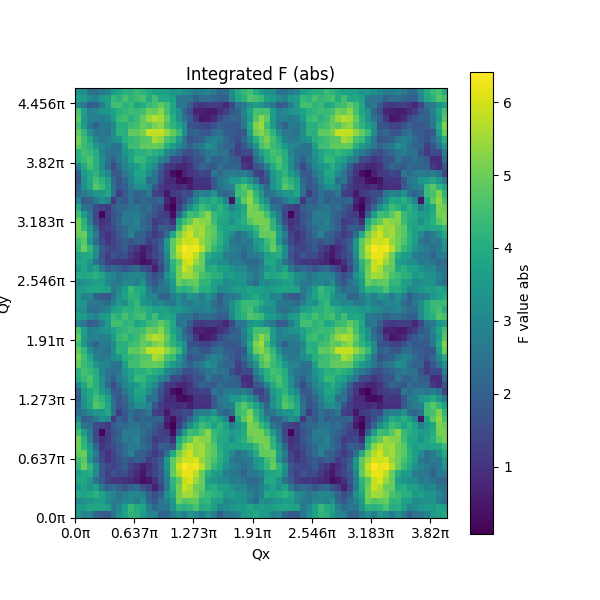

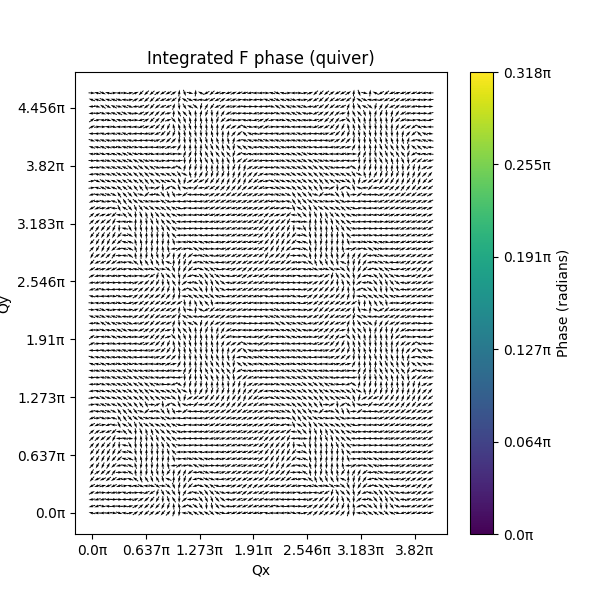

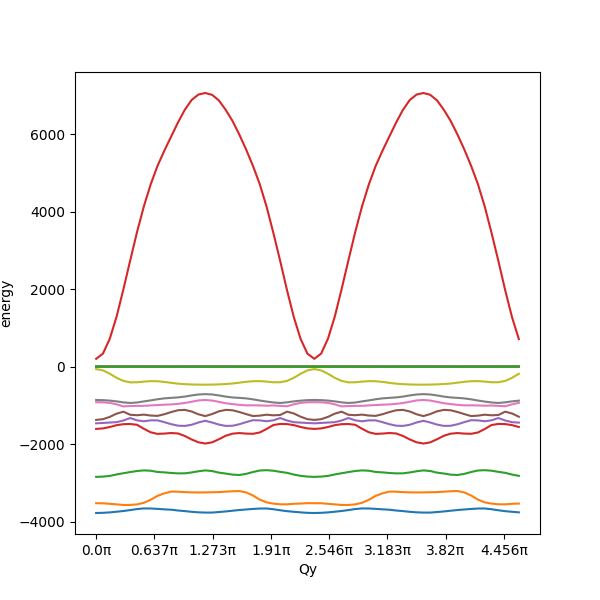

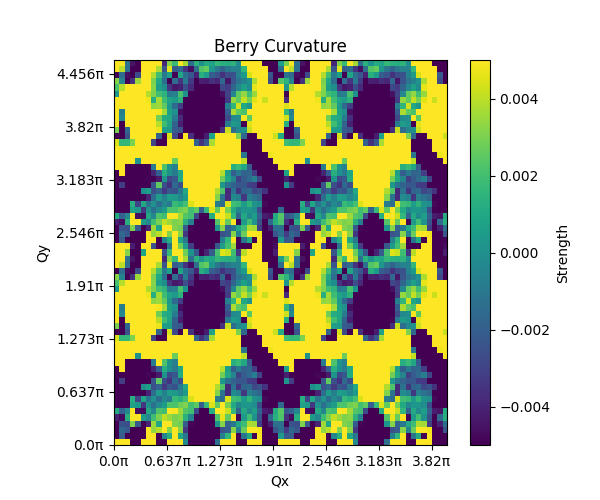

In [230]:
abs_integrated_f_matrix = np.abs(integrated_f[:,:,0])
phase_integrated_f_matrix = np.angle(integrated_f[:,:,0])
GraphIntegratedF(abs_integrated_f_matrix,load_folder)
GraphFPhaseQuiver(phase_integrated_f_matrix,load_folder)
GraphQxConst(eQ,load_folder)
Graph3D(eQ,1,load_folder)
BC,C = GetBerryCurvature1band(F0)
GraphBerryCurvature(BC,C,load_folder)
print(C)

# misc

In [60]:
def add_title_to_image(image_path, title, font_size=40, padding=10):
    image = Image.open(image_path)
    width, height = image.size

    # Height for the title space, which includes padding
    title_height = font_size + 2 * padding

    # Create a new image with extra space for the title (white background)
    new_image = Image.new("RGB", (width, height + title_height), "white")

    # Paste the original image below the title space
    new_image.paste(image, (0, title_height))  # (0, title_height) places the image below the title area

    # Draw the title
    draw = ImageDraw.Draw(new_image)

    try:
        # Attempt to load a font, otherwise fallback to default
        font = ImageFont.truetype("arial.ttf", font_size)
    except IOError:
        font = ImageFont.load_default()  # Fallback to default if Arial is missing

    # Use textbbox() to get text size
    bbox = draw.textbbox((0, 0), title, font=font)
    text_width = bbox[2] - bbox[0]
    text_height = bbox[3] - bbox[1]

    # Center the text within the title space
    text_x = (width - text_width) // 2  # Horizontally center
    text_y = (title_height - text_height) // 2  # Vertically center with padding

    # Draw the title in black for visibility
    draw.text((text_x, text_y), title, fill="black", font=font)

    return new_image

In [73]:
def MakeGifs(Ms,Cs):
    # Define input and output folders
    image_folder = Path("Images/HW")
    output_folder = Path("Gifs/HW")
    os.makedirs(output_folder, exist_ok=True)  # Ensure output folder exists
    
    # Here write an array for whatever variable
    #Nk_range =  list(range(8,16,2))
    #U_range = list(range(8, 25, 4))
    #epsilon_range = [1e-2,1e-3,1e-4,1e-5]
    # Define constants
    #_N = "14"
    #_epsilon = "1e-05"
    #_U = "16" 
    #_M = "-1.1"
    matching_images=[]
    for M in Ms:
        #ChernInsulator-Bands, M={M}.png
        #ChernInsulator-BC,M={M}.png
        file_path = image_folder / f"ChernInsulator-Bands, M={M}.png"
        if file_path.exists():
            matching_images.append(file_path)
        else:
            print("File not found:", file_path)
    
    processed_images = []
    for img_path in matching_images:
        match = re.search(r"M=([-+]?[0-9]*\.?[0-9]+)", img_path.name)
        if match:
            M_value = float(match.group(1))
            print("Extracted M:", M_value)
        else:
            print("M value not found in filename")
        C= np.real(np.round(Cs[np.where(np.isclose(Ms, M_value))[0][0]],3))
        title = f"M = {np.round(M_value,1)}, C={C}" #TODO HW add C_n to title
        new_img = add_title_to_image(img_path, title)
        processed_images.append(new_img)
    
    if len(processed_images)>0:
        # Open the first image as the base
        #frames = [Image.open(img) for img in processed_images]
        
        # Save as GIF (loop=0 makes it loop indefinitely)
        output_gif_path = os.path.join(output_folder, f"Changing M - Bands.gif")
        #frames[0].save(output_gif_path, save_all=True, append_images=frames[1:], duration=500, loop=0)
        processed_images[0].save(output_gif_path, save_all=True, append_images=processed_images[1:], duration=500, loop=0)
        print("GIF saved as:", output_gif_path)
    else:
        print("No matching images found, GIF not created.")

In [134]:
def combine_gifs_side_by_side(gif1_path, gif2_path, output_path):
    gif1 = Image.open(gif1_path)
    gif2 = Image.open(gif2_path)

    # Convert all frames to RGB to avoid palette issues
    frames1 = [frame.convert("RGB") for frame in ImageSequence.Iterator(gif1)]
    frames2 = [frame.convert("RGB") for frame in ImageSequence.Iterator(gif2)]

    if len(frames1) != len(frames2):
        raise ValueError("GIFs must have the same number of frames")

    combined_frames = []

    for f1, f2 in zip(frames1, frames2):
        # Resize to match height
        if f1.height != f2.height:
            new_height = min(f1.height, f2.height)
            f1 = f1.resize(
                (int(f1.width * new_height / f1.height), new_height),
                Image.Resampling.LANCZOS
            )
            f2 = f2.resize(
                (int(f2.width * new_height / f2.height), new_height),
                Image.Resampling.LANCZOS
            )

        # Combine side by side
        combined_width = f1.width + f2.width
        combined = Image.new("RGB", (combined_width, f1.height))
        combined.paste(f1, (0, 0))
        combined.paste(f2, (f1.width, 0))
        combined_frames.append(combined)

    # Save as palette-based GIF ("P" mode)
    combined_frames = [frame.convert("P", palette=Image.ADAPTIVE) for frame in combined_frames]

    combined_frames[0].save(
        output_path,
        save_all=True,
        append_images=combined_frames[1:],
        duration=gif1.info.get("duration", 100),
        loop=0,
        disposal=2
    )

# Example usage
combine_gifs_side_by_side(
    Path("Gifs/HW/Changing M - Bands.gif"),
    Path("Gifs/HW/Changing M - BC.gif"),
    Path("Gifs/HW/Changing M.gif")
)


## tests

In [57]:
integrated_f_matrix = np.abs(integrated_f_matrix)
rows, cols, n = integrated_f_matrix.shape
center_row = rows // 2
center_col = cols // 2
for i in range(2):
    line1 = [integrated_f_matrix[center_row + j-1, center_row + j-1,i] for j in range(center_plus1)]
    line2 = [integrated_f_matrix[rows-1, rows - j-2,i] for j in range(center_plus1-1)]
    line3 = [integrated_f_matrix[rows - j-2, center_row-1,i] for j in range(center_plus1-1)]
    band = line1 + line2 + line3
    plt.plot(band, label = f"band {i}")
xticks_positions = [
    0,                      # Start of the first line
    len(line1)-1,         # End of the first line
    len(line1) + len(line2)-2,  # End of the second line
    len(band)-1          # End of the third line
]
xtick_labels = [r"$\Gamma$", r"M", r"X", r"$\Gamma$"]
# Set custom xticks
plt.xticks(ticks=xticks_positions, labels=xtick_labels)
plt.ylabel("integrated F")
plt.legend()
plt.show()

NameError: name 'center_plus1' is not defined

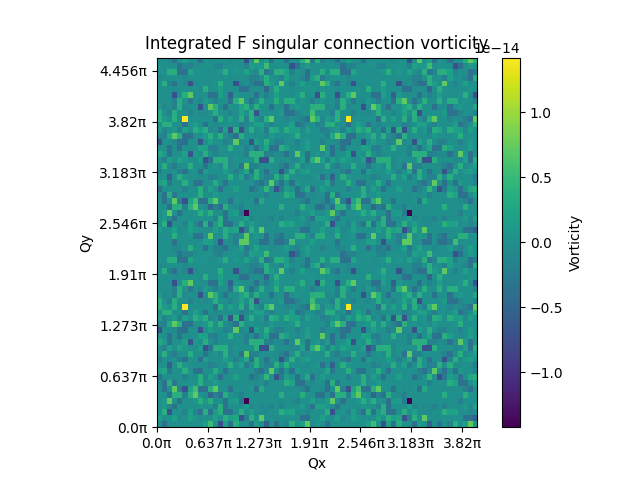

In [228]:
GraphFVorticity(integrated_f[:,:,0],load_folder)

In [225]:
eps = 1e-2  # tolerance for "almost zero"
has_real = np.any(np.abs(np.real(vor)) > eps)
only_imag = np.all(np.abs(np.real(vor)) < eps)
print(has_real)
print(only_imag)

False
True


In [218]:
logF = np.log(integrated_f[:,:,0])
Qxlist = sys_dict["Qxlist"]
Qylist = sys_dict["Qylist"]
dQx = np.abs(Qxlist[1] - Qxlist[0])
dQy = np.abs(Qylist[1] - Qylist[0])
u,v = periodic_gradient(logF,dQx,dQy)
vor = periodic_vorticity(np.real(1j*u),np.real(1j*v),dQx,dQy)
real_mask = np.abs(np.real(vor)) > eps
imag_mask = ~real_mask
n_real = np.count_nonzero(real_mask)
n_imag = np.count_nonzero(imag_mask)

# Indices of real entries
real_indices = np.argwhere(real_mask)
imag_indices = np.argwhere(imag_mask)

print("Number of real entries:", n_real)
print("Real indices:", real_indices)

print("Number of (purely) imaginary entries:", n_imag)
print("Imag indices:", imag_indices)

Number of real entries: 0
Real indices: []
Number of (purely) imaginary entries: 3969
Imag indices: [[ 0  0]
 [ 0  1]
 [ 0  2]
 ...
 [62 60]
 [62 61]
 [62 62]]


In [229]:
for index in imag_indices:
    print(vor[index[0],index[1]])

0.0
-3.552713678800501e-15
0.0
0.0
0.0
0.0
0.0
0.0
1.1102230246251565e-16
1.7763568394002505e-15
5.329070518200751e-15
0.0
-7.105427357601002e-15
1.7763568394002505e-15
-3.552713678800501e-15
3.552713678800501e-15
0.0
0.0
-3.552713678800501e-15
1.3322676295501878e-15
0.0
-5.329070518200751e-15
0.0
-3.552713678800501e-15
0.0
-1.4432899320127035e-15
3.552713678800501e-15
0.0
1.7763568394002505e-15
7.105427357601002e-15
-6.661338147750939e-16
7.008282842946301e-16
0.0
-3.552713678800501e-15
0.0
0.0
0.0
0.0
0.0
0.0
1.1102230246251565e-16
1.7763568394002505e-15
5.329070518200751e-15
0.0
-7.105427357601002e-15
1.7763568394002505e-15
-3.552713678800501e-15
3.552713678800501e-15
0.0
0.0
-3.552713678800501e-15
1.3322676295501878e-15
0.0
-5.329070518200751e-15
0.0
-3.552713678800501e-15
0.0
-1.4432899320127035e-15
3.552713678800501e-15
0.0
1.7763568394002505e-15
7.105427357601002e-15
5.551115123125783e-16
1.7763568394002505e-15
0.0
0.0
1.7763568394002505e-15
-7.077671781985373e-16
0.0
1.77635683

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



3.677613769070831e-15
0.0
-1.7763568394002505e-15
-1.4988010832439613e-15
3.552713678800501e-15
-2.220446049250313e-16
3.552713678800501e-15
0.0
-1.1102230246251565e-16
0.0
-4.440892098500626e-16
0.0
7.277164981722706e-16
-3.552713678800501e-15
0.0
-5.329070518200751e-15
0.0
3.552713678800501e-15
7.771561172376096e-16
0.0
0.0
-1.1102230246251565e-16
0.0
-1.7763568394002505e-15
-9.454242944073599e-16
0.0
0.0
3.552713678800501e-15
0.0
1.7763568394002505e-15
-2.6645352591003757e-15
0.0
3.677613769070831e-15
0.0
-1.7763568394002505e-15
-1.4988010832439613e-15
3.552713678800501e-15
-2.220446049250313e-16
3.552713678800501e-15
0.0
-1.1102230246251565e-16
0.0
-4.440892098500626e-16
-2.220446049250313e-15
-1.7763568394002505e-15
0.0
-4.440892098500626e-16
0.0
-1.7763568394002505e-15
-3.552713678800501e-15
1.6653345369377348e-16
2.220446049250313e-16
-3.552713678800501e-15
1.4432899320127035e-15
0.0
0.0
0.0
1.7763568394002505e-15
0.0
-1.7763568394002505e-15
0.0
2.6645352591003757e-15
-3.5527136

8


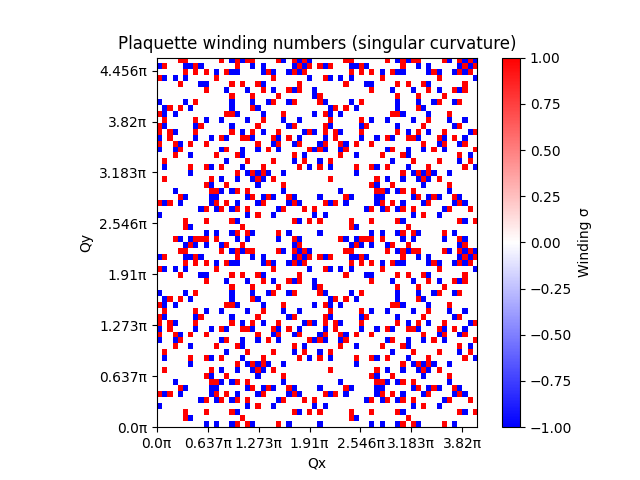

In [239]:
def plaquette_winding_map_periodic(F, Qxlist, Qylist, output_folder):
    """
    Compute integer winding numbers of F(Q) phase around each plaquette,
    taking into account periodic boundary conditions in both directions.
    Returns a (ny, nx) array of integers (one per plaquette).
    """
    ny, nx = F.shape
    windings = np.zeros((ny, nx))

    for iy in range(ny):
        for ix in range(nx):
            # periodic indices
            ixp = (ix + 1) % nx
            iyp = (iy + 1) % ny

            loop = [F[iy, ix], F[iy, ixp], F[iyp, ixp], F[iyp, ix]]
            phases = np.angle(loop)
            #dphi = np.diff(np.unwrap(phases))
            dphi = np.diff(phases)
            winding = (np.sum(dphi) / (2*np.pi))
            windings[iy, ix] = winding

    # Plot
    fig, ax = plt.subplots()
    extent = [Qxlist[0], Qxlist[-1], Qylist[0], Qylist[-1]]
    im = ax.imshow(windings.T, origin="lower", extent=extent,
                   aspect="equal", cmap="bwr",)

    ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
    ax.yaxis.set_major_formatter(FuncFormatter(PiFormatter))
    ax.set_xlabel("Qx")
    ax.set_ylabel("Qy")
    ax.set_title("Plaquette winding numbers (periodic BZ)")
    cb = plt.colorbar(im, ax=ax, label="Winding σ")

    output_path = os.path.join(output_folder, "Plaquette_windings_periodic.png")
    fig.savefig(output_path)

    return windings

windings = plaquette_winding_map(integrated_f[:,:,0],Qxlist,Qylist,load_folder)
print(np.sum(windings))

In [ ]:
#תכייל את כל הF אולי?